# Лабораторная 1: графики

Читает CSV из `results/` и сохраняет PNG для `README.md`.

- `results/sizes.csv`: все версии на всех размерах; последовательные - в 1
  поток, параллельные - в 11.
- `results/scaling.csv`: параллельные версии при $n = 2048$ и $4096$,
  $p = 1 \dots 11$ потоков.

Каждая конфигурация мерилась в нескольких запусках. Точка - минимальное время
по всем повторам, планка погрешности - до наибольшего среднего по запуску.

Перезапуск из корня репозитория:
`.venv/bin/jupyter nbconvert --to notebook --execute --inplace lab_1/plots.ipynb`

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import make_smoothing_spline

RESULTS = Path("results")
ORDER = ["naive", "transposed", "blocked", "strassen",
         "blocked_omp", "simd", "simd_omp", "best"]
PARALLEL = ["blocked_omp", "simd_omp", "best"]
COLORS = dict(zip(ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                          "#e87ba4", "#008300", "#4a3aa7", "#e34948"]))
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})


def load(name):
    df = pd.read_csv(RESULTS / name)
    return (df.groupby(["variant", "n", "threads"])
              .agg(min_s=("min_s", "min"), mean_s=("mean_s", "max"))
              .reset_index())


def errorbar(ax, x, y, other, color, label=None, marker="o"):
    yerr = [np.clip(y - other, 0, None), np.clip(other - y, 0, None)]
    ax.errorbar(x, y, yerr=yerr, fmt=marker, color=color, ms=5, capsize=3,
                elinewidth=1, label=label)


sizes = load("sizes.csv")
scaling = load("scaling.csv")

## Время и производительность в зависимости от размера

Время умножения подчиняется степенному закону $t = c\,n^k$ ($k = 3$ для
классического алгоритма, $k = \log_2 7 \approx 2.81$ для Штрассена), то есть
в координатах $(\log n, \log t)$ это прямая. Прямые построены методом
наименьших квадратов по $\log t = \log c + k \log n$ на участке, где закон
выполняется:

- `naive` - до $n = 2048$: при $4096$ столбцы $B$ перестают помещаться в
  кэш, и точка уходит вверх;
- `simd` - от $256$, `blocked_omp` - от $512$, `simd_omp` и `best` - от
  $1024$: при меньших $n$ время определяют накладные расходы (края упаковки,
  запуск потоков), а не $n^3$.

Прямые продлены на весь диапазон $n$; точки вне участка считаются выбросами
и в МНК не учитываются. Производительность
$\mathrm{GFLOPS} = 2n^3 / t$ по той же модели тоже прямая с наклоном
$3 - k$.

In [2]:
FIT_FROM = {"simd": 256, "blocked_omp": 512, "simd_omp": 1024, "best": 1024}
FIT_TO = {"naive": 2048}


def power_fit(v, g):
    """МНК-прямая log t = log c + k log n на участке степенного закона."""
    lo, hi = FIT_FROM.get(v, 0), FIT_TO.get(v, 10**9)
    part = g[(g.n >= lo) & (g.n <= hi)]
    k, log_c = np.polyfit(np.log(part.n), np.log(part.min_s), 1)
    return k, np.exp(log_c), part.n.min(), part.n.max()


fits = {}
for v in ORDER:
    fits[v] = power_fit(v, sizes[sizes.variant == v])
pd.DataFrame({v: {"k": round(f[0], 3), "n от": f[2], "n до": f[3]}
              for v, f in fits.items()}).T

,k,n от,n до
naive,3.247,64.0,2048.0
transposed,3.197,64.0,4096.0
blocked,3.067,64.0,4096.0
strassen,2.839,64.0,4096.0
blocked_omp,2.910,512.0,4096.0
simd,2.988,256.0,4096.0
simd_omp,2.958,1024.0,4096.0
best,2.910,1024.0,4096.0


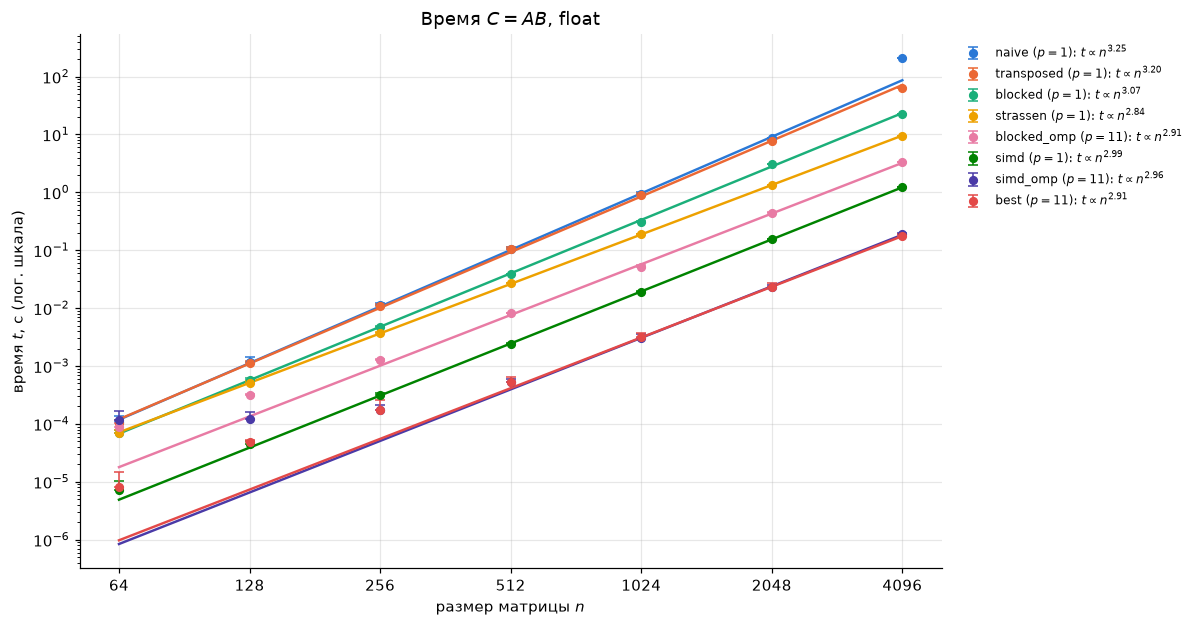

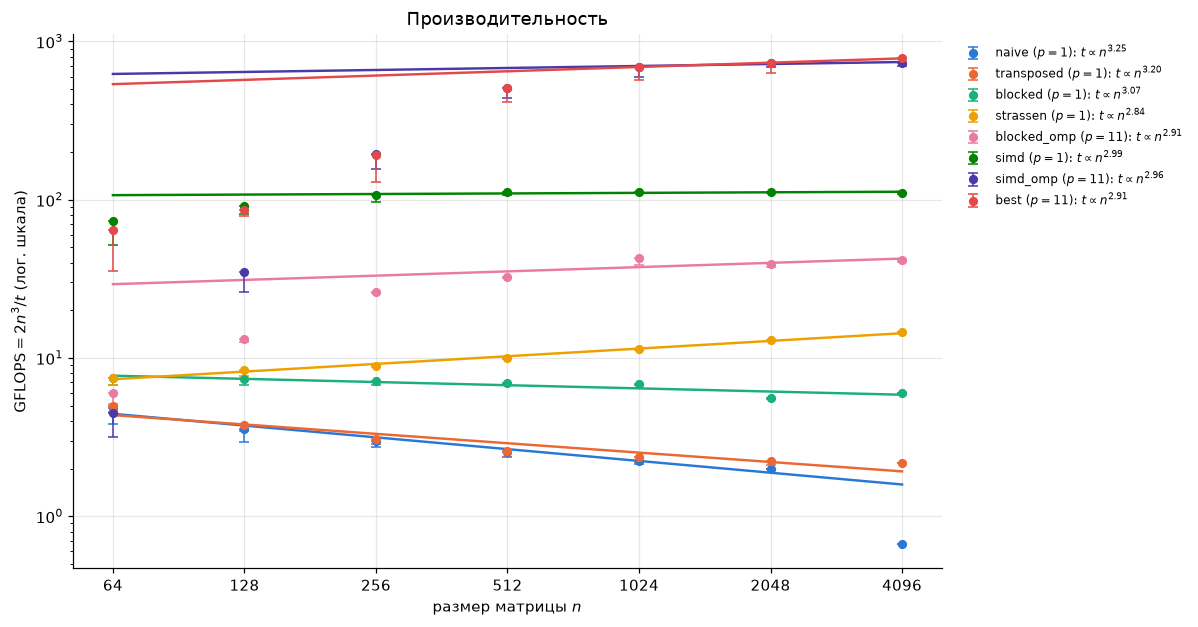

In [3]:
def plot_sizes(metric, ylabel, title, fname):
    fig, ax = plt.subplots(figsize=(11, 5.8))
    for v in ORDER:
        g = sizes[sizes.variant == v].sort_values("n")
        n = g.n.to_numpy(float)
        t, mean = g.min_s.to_numpy(), g.mean_s.to_numpy()
        k, c, lo, hi = fits[v]
        ns = np.geomspace(sizes.n.min(), sizes.n.max(), 50)
        if metric == "time":
            y, other, line = t, mean, c * ns**k
        else:
            y, other = 2e-9 * n**3 / t, 2e-9 * n**3 / mean
            line = 2e-9 * ns**3 / (c * ns**k)
        p = g.threads.iloc[0]
        label = rf"{v} ($p={p}$): $t \propto n^{{{k:.2f}}}$"
        errorbar(ax, n, y, other, COLORS[v], label)
        ax.plot(ns, line, color=COLORS[v], lw=1.6)
    ticks = sorted(sizes.n.unique())
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xticks(ticks, [str(n) for n in ticks])
    ax.set_xlabel("размер матрицы $n$")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(fontsize=8, frameon=False, loc="upper left",
              bbox_to_anchor=(1.01, 1))
    fig.tight_layout()
    fig.savefig(RESULTS / fname)
    plt.show()


plot_sizes("time", "время $t$, с (лог. шкала)",
           r"Время $C = AB$, float", "time_vs_size.png")
plot_sizes("gflops", r"$\mathrm{GFLOPS} = 2n^3 / t$ (лог. шкала)",
           "Производительность", "gflops_vs_size.png")

In [4]:
sizes.pivot(index="n", columns="variant", values="min_s")[ORDER]

variant,naive,transposed,blocked,strassen,blocked_omp,simd,simd_omp,best
n,,,,,,,,
64,0.000108,0.000105,0.000070,0.000070,0.000087,0.000007,0.000117,0.000008
128,0.001175,0.001112,0.000567,0.000503,0.000318,0.000046,0.000120,0.000049
256,0.011312,0.010881,0.004722,0.003772,0.001276,0.000315,0.000172,0.000176
512,0.105610,0.104642,0.038715,0.026815,0.008218,0.002416,0.000530,0.000526
1024,0.955506,0.911477,0.312264,0.188505,0.050501,0.019123,0.003101,0.003116
2048,8.633143,7.713088,3.091669,1.330655,0.440155,0.153508,0.023336,0.023332
4096,205.987561,63.401546,23.033272,9.422493,3.324264,1.241911,0.187311,0.175975


## Ускорение и эффективность

$$S(p) = \frac{T(1)}{T(p)}, \qquad E(p) = \frac{S(p)}{p},$$

где $T(1)$ - та же версия в 1 поток. Степенного закона здесь нет, поэтому
кривая - сглаживающий кубический сплайн времени в координатах
$(\log p, \log T)$, а кривые $S$ и $E$ получены из него. Вертикальная линия -
5 производительных ядер.

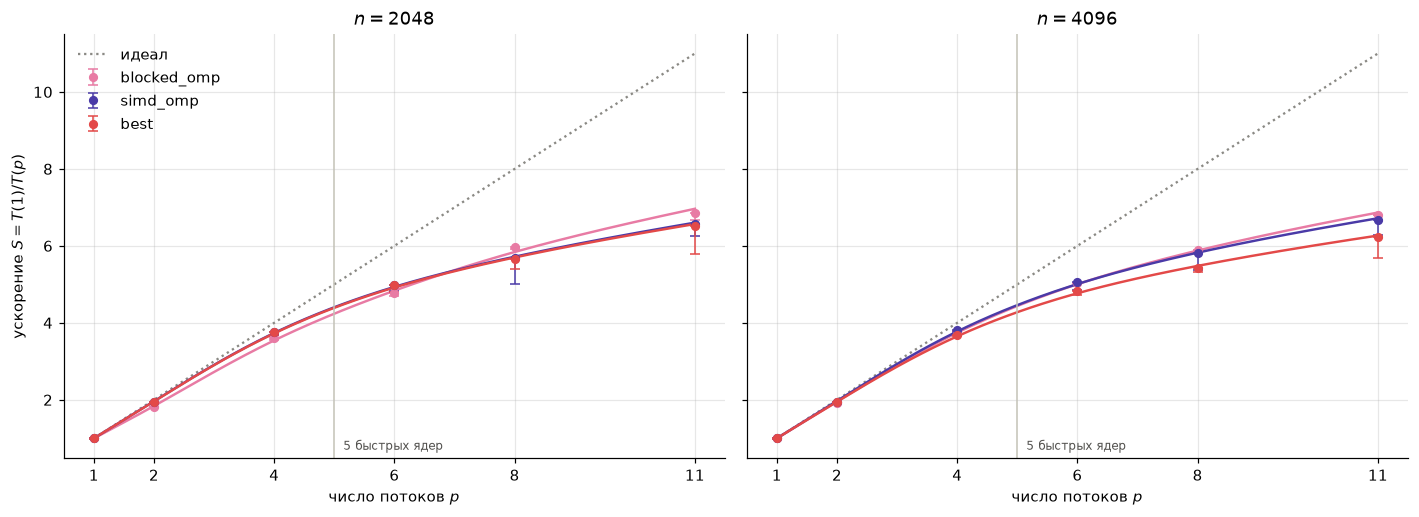

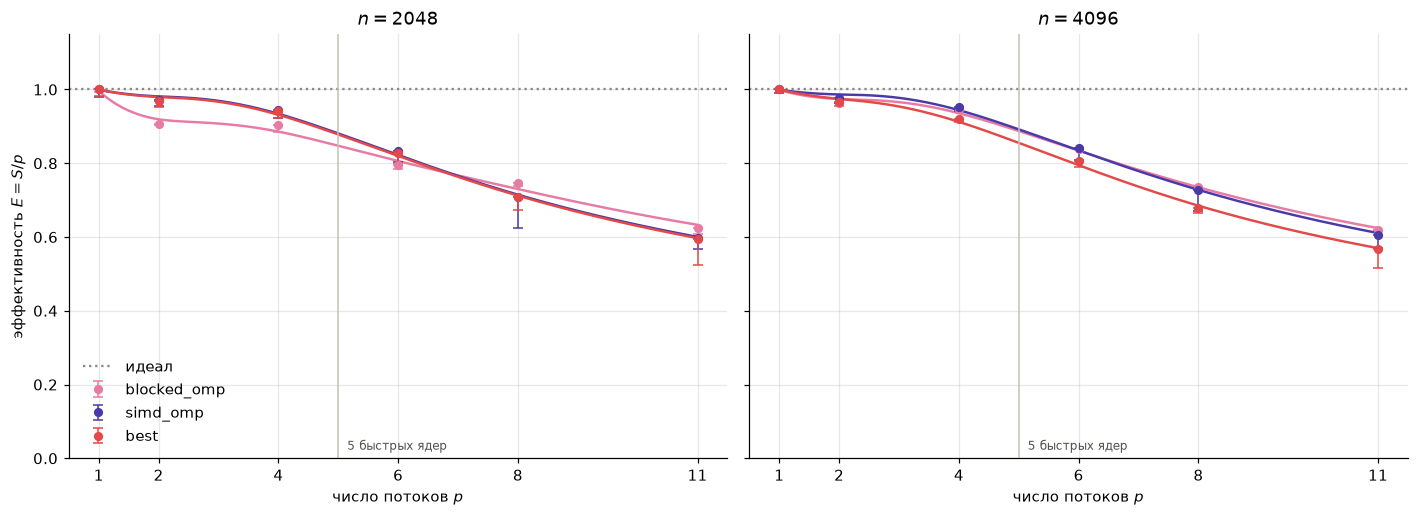

In [5]:
def fit_loglog(x, t, xs):
    """Сглаживающий сплайн времени в координатах (log x, log t)."""
    spline = make_smoothing_spline(np.log(x), np.log(t), lam=0.01)
    return np.exp(spline(np.log(xs)))


def plot_scaling(metric, title, fname):
    ps_all = sorted(scaling.threads.unique())
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
    for ax, n in zip(axes, sorted(scaling.n.unique())):
        if metric == "S":
            ax.plot(ps_all, ps_all, color="#8a8984", ls=":", lw=1.5,
                    label="идеал")
        else:
            ax.axhline(1, color="#8a8984", ls=":", lw=1.5, label="идеал")
        for v in PARALLEL:
            g = scaling[(scaling.variant == v) & (scaling.n == n)]
            g = g.sort_values("threads")
            p = g.threads.to_numpy(float)
            t, mean = g.min_s.to_numpy(), g.mean_s.to_numpy()
            div = p if metric == "E" else 1
            errorbar(ax, p, t[0] / t / div, t[0] / mean / div, COLORS[v], v)
            ps = np.linspace(1, p.max(), 200)
            tf = fit_loglog(p, t, ps)
            ax.plot(ps, t[0] / tf / (ps if metric == "E" else 1),
                    color=COLORS[v], lw=1.6)
        ax.axvline(5, color="#c3c2b7", lw=1)
        ax.text(5.15, 0.02, "5 быстрых ядер", fontsize=8, color="#52514e",
                transform=ax.get_xaxis_transform())
        ax.set_xticks(ps_all)
        ax.set_xlabel("число потоков $p$")
        ax.set_title(f"$n = {n}$")
    axes[0].set_ylabel(title)
    if metric == "E":
        axes[0].set_ylim(0, 1.15)
    axes[0].legend(frameon=False)
    fig.tight_layout()
    fig.savefig(RESULTS / fname)
    plt.show()


plot_scaling("S", "ускорение $S = T(1) / T(p)$", "speedup.png")
plot_scaling("E", "эффективность $E = S / p$", "efficiency.png")

In [6]:
t1 = scaling[scaling.threads == 1].set_index(["variant", "n"]).min_s
scaling["S"] = [t1[(v, n)] / t for v, n, t in
                zip(scaling.variant, scaling.n, scaling.min_s)]
scaling["E"] = scaling.S / scaling.threads
scaling.pivot_table(index=["variant", "n"], columns="threads",
                    values=["S", "E"]).round(2)

E                                  S                    \
threads            1     2     4     6     8     11   1     2     4     6    
variant     n                                                                
best        2048  1.0  0.97  0.94  0.83  0.71  0.59  1.0  1.94  3.76  4.97   
            4096  1.0  0.97  0.92  0.80  0.68  0.57  1.0  1.93  3.68  4.83   
blocked_omp 2048  1.0  0.91  0.90  0.79  0.75  0.62  1.0  1.81  3.61  4.76   
            4096  1.0  0.96  0.95  0.84  0.74  0.62  1.0  1.93  3.79  5.03   
simd_omp    2048  1.0  0.97  0.94  0.83  0.71  0.60  1.0  1.94  3.77  5.00   
            4096  1.0  0.98  0.95  0.84  0.73  0.61  1.0  1.95  3.81  5.05   

                              
threads             8     11  
variant     n                 
best        2048  5.66  6.53  
            4096  5.44  6.23  
blocked_omp 2048  5.97  6.87  
            4096  5.88  6.81  
simd_omp    2048  5.67  6.57  
            4096  5.81  6.67